# 7. Period doubling from a simulated orbit

Period-doubling cascade in the Roessler system [10.1016/0375-9601(76)90101-8]

```text
    x' = -y - z,   y' = x + a y,   z' = b + z (x - c),   a = b = 0.2,  c varies.
```

Shows how to start AUTO on a periodic orbit found by simulation (there is
no Hopf point to start from here):

```text
  1. integrate past the transient,
  2. measure the period from two crossings of the section y = 0,
  3. integrate exactly one period starting on the section,
  4. AUTO "Periodic" start: XPP reads the orbit and its period from the
     data browser.
```

Then grab each PD point and choose "doubling" to follow the doubled orbit.
The ratio of successive PD spacings approaches Feigenbaum's 4.669...
[10.1007/BF01020332]; three PD points give only a rough first estimate.
The script version writes auto_period_doubling.png.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pyxpp

m = pyxpp.load(text="""
x'=-y-z
y'=x+a*y
z'=b+z*(x-c)
par a=0.2,b=0.2,c=2.5
init x=1,y=1,z=0
@ total=1000,dt=0.005,trans=900,maxstor=100000
done
""")

## 1-2. find the period-1 orbit at c = 2.5 and its period

In [2]:
tr = m.run()
y, t = tr["y"], tr.t
up = np.where((y[:-1] < 0) & (y[1:] >= 0))[0]          # upward crossings of y = 0


def crossing(k):
    """linear interpolation of the state at the crossing between rows k, k+1"""
    s = -y[k] / (y[k + 1] - y[k])
    return t[k] + s * (t[k + 1] - t[k]), {v: tr[v][k] + s * (tr[v][k + 1] - tr[v][k])
                                          for v in m.vars}


t1, start = crossing(up[-2])
t2, _ = crossing(up[-1])
period = t2 - t1
print(f"period-1 orbit at c = 2.5: T = {period:.4f}")

period-1 orbit at c = 2.5: T = 5.7490


## 3. exactly one period, starting on the section

In [3]:
m.set(trans=0, total=period, **start)
one = m.run()

## 4. continue the orbit in c

In [4]:
p1 = m.auto.run("c", start="periodic", ntst=50, ds=0.01, dsmax=0.05,
                nmax=300, parmin=2, parmax=4.5)
pd_points = []
branches = [p1]
for k in range(3):                       # period 1 -> 2 -> 4 -> 8
    pds = branches[-1].special("PD")
    if not pds:
        break
    pd = pds[0]
    pd_points.append(pd)
    print(f"PD {k + 1}: c = {pd.x:.5f}, period {pd.period:.4f}")
    branches.append(m.auto.run(grab=pd.label, choice="doubling", nmax=300))

c_pd = np.array([p.x for p in pd_points])
if len(c_pd) >= 3:
    print(f"(c2 - c1) / (c3 - c2) = {(c_pd[1] - c_pd[0]) / (c_pd[2] - c_pd[1]):.3f}")

PD 1: c = 2.83246, period 5.7698


PD 2: c = 3.83736, period 11.5727


PD 3: c = 4.12421, period 23.2026


(c2 - c1) / (c3 - c2) = 3.503


## plots

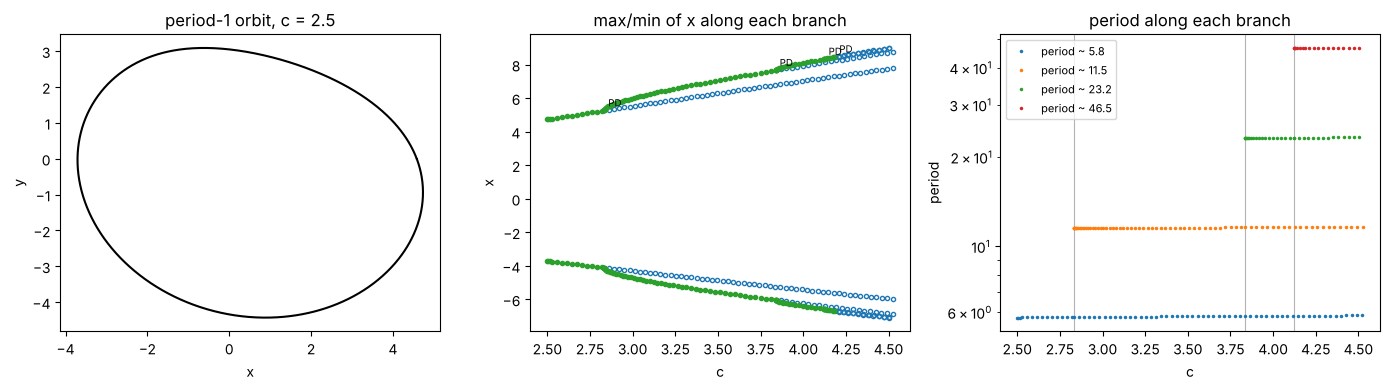

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(one["x"], one["y"], "k")
axs[0].set(title="period-1 orbit, c = 2.5", xlabel="x", ylabel="y")

m.auto.diagram.plot(y="x", ax=axs[1])
axs[1].set(title="max/min of x along each branch")

for br, col in zip(branches, ["C0", "C1", "C2", "C3"]):
    axs[2].plot([p.x for p in br], [p.period for p in br], ".", color=col, ms=3,
                label=f"period ~ {br[len(br) // 2].period:.1f}")
for p in pd_points:
    axs[2].axvline(p.x, color="0.7", lw=0.8, zorder=0)
axs[2].set(title="period along each branch", xlabel="c", ylabel="period", yscale="log")
axs[2].legend(fontsize=8)

fig.tight_layout()